### **Convolutional Neural Network (CNN)**

In [19]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import random_split, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.utils import make_grid

CNN (Convolutional Neural Network) განსაკუთრებით ეფექტურია სურათების დამუშავებისთვის (PyTorch-ის `nn.Conv2d` ფენა).

convolution ოპერაცია: 
convolution არის ცენტრალური ოპერაცია CNN–ში, რომლის დროსაც ფილტრი (kernel) გადაადგილდება input სურათზე. კერნელი წარმოადგენს პატარა წონებიან მატრიცას. კერნელი გადაინაცვლებს 2D შეყვანილ მონაცემებზე, აწარმოებს ელემენტურ გამრავლებას კერნელის თითოეული წონისა და input-ის აღნიშნული უბნის შესაბამისი ელემენტებს შორის, შემდეგ შეკრებს გადამრავლებულ მნიშვნელობებს, რათა მიიღოს ერთი გამომავალი პიქსელი.:

$$
  (I * K)(x,y) = \sum_{i=-a}^{a} \sum_{j=-b}^{b} I(x+i,\; y+j)\,K(i,j)
$$

აქ $I$ არის შეყვანილი სიგნალი (სურათი), $K$ — k×k ზომის ფილტრი, $a=b=\lfloor k/2\rfloor$. შედეგად ვიღებთ feature map.

<img src="https://miro.medium.com/max/1070/1*Zx-ZMLKab7VOCQTxdZ1OAw.gif" style="max-width:400px;">

განვიხილოთ მაგალითი, 1-არხიანი (5×5) სურათი და (3×3) კერნელი:

In [20]:
def apply_kernel(image, kernel):
    ri, ci = image.shape       # image dimensions
    rk, ck = kernel.shape      # kernel dimensions
    ro, co = ri-rk+1, ci-ck+1  # output dimensions
    output = torch.zeros([ro, co])
    for i in range(ro): 
        for j in range(co):
            output[i,j] = torch.sum(image[i:i+rk,j:j+ck] * kernel)
    return output

In [21]:
# 1-არხიანი (5×5) სურათი
sample_image = torch.tensor([
    [3, 3, 2, 1, 0], 
    [0, 0, 1, 3, 1], 
    [3, 1, 2, 2, 3], 
    [2, 0, 0, 2, 2], 
    [2, 0, 0, 0, 1]
], dtype=torch.float32)

# (3×3) კერნელი
sample_kernel = torch.tensor([
    [1, 0, -1], 
    [1, 0, -1], 
    [1, 0, -1]
], dtype=torch.float32)

# (5×5) სურათი -> (3×3) output
apply_kernel(sample_image, sample_kernel)

tensor([[ 1., -2.,  1.],
        [ 2., -6., -3.],
        [ 5., -3., -4.]])

კერნელთან მიმართებაში შემდეგი ორი პარამეტრია მნიშვნელოვანი:
* stride – ფილტრის გადაადგილების ნაბიჯი
* padding – შეყვანილი სურათის ჩარჩოზე ნულებით გარშემორტყმა

<img src="../../images/stride.png" width="500">

In [22]:
# Conv2d შრე:
conv_layer = nn.Conv2d(
    in_channels=1,     # არხების რაოდენობა input-ში
    out_channels=1,   # არხების რაოდენობა output-ში
    kernel_size=3,     # (3×3) კერნელი
    stride=1,          
    padding=0
)

In [23]:
# Your custom kernel
my_kernel = torch.tensor([[[[ 1,  0, -1],
                            [ 1,  0, -1],
                            [ 1,  0, -1]]]], dtype=torch.float32)

# Overwrite the conv layer’s weights
with torch.no_grad():
    conv_layer.weight.copy_(my_kernel)

In [24]:
# unsqueeze for batch [5, 5] -> [1, 5, 5]
sample_image = sample_image.unsqueeze(0)
# unsqueeze for channel [1, 5, 5] -> [1, 1, 5, 5]
sample_image = sample_image.unsqueeze(1) 

conv_layer(sample_image).shape   # torch.Size([1, 1, 3, 3])

torch.Size([1, 1, 3, 3])

In [25]:
# ან პირდაპირ F.conv2d-ის საშუალებით:
output = F.conv2d(sample_image, my_kernel, bias=None, stride=1, padding=0)
output

tensor([[[[ 1., -2.,  1.],
          [ 2., -6., -3.],
          [ 5., -3., -4.]]]])

Pooling: Pooling ამცირებს სივრცულ განზომილებას და აძლიერებს მოდელის ინვარიანტულობას მცირე გადაადგილებების მიმართ.

* Max Pooling – არჩევს მაქსიმალურ მნიშვნელობას k×k ბლოკიდან
* Average Pooling – ამოღებს საშუალოს

<img src="https://computersciencewiki.org/images/8/8a/MaxpoolSample2.png" style="max-width:300px;">

In [26]:
output

tensor([[[[ 1., -2.,  1.],
          [ 2., -6., -3.],
          [ 5., -3., -4.]]]])

In [27]:
pool = nn.MaxPool2d(kernel_size=2, stride=1)
pool(output)

tensor([[[[ 2.,  1.],
          [ 5., -3.]]]])

In [28]:
simple_model = nn.Sequential(
    nn.Conv2d(3, 3, kernel_size=3, stride=2, padding=1), # convolutional layer with 3 channels
    nn.MaxPool2d(2, 1) # 2x2 Max-Pool
)

<img src="../../images/cnn.png">

In [29]:
# generate a random image: batch_size=1, channels=3, height=32, width=32
input_tensor = torch.rand(1, 3, 32, 32)

# forward pass
output = simple_model(input_tensor)

print("Input shape: ", input_tensor.shape)   
print("Output shape:", output.shape)         

Input shape:  torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 3, 15, 15])


### CIFAR10 Dataset

CIFAR10 მონაცემები შეიცავს 60000 32x32 პიქსელიან ფერად სურათებს 10 სხვადასხვა კლასიდან

<img src="https://miro.medium.com/max/709/1*LyV7_xga4jUHdx4_jHk1PQ.png" style="max-width:480px">

In [32]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

trainset = torchvision.datasets.CIFAR10(
    root="../../datasets", train=True, download=True, transform=transform)

train_dataset, val_dataset = random_split(
    trainset,
    [40000, 10000],
    generator=torch.Generator().manual_seed(42)
)

train_dataloader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=4
)
val_dataloader = DataLoader(
    val_dataset, batch_size=64, shuffle=False, num_workers=4
)

testset = torchvision.datasets.CIFAR10(
    root="../../datasets", train=False, download=True, transform=transform)
test_dataloader = DataLoader(testset, batch_size=64, shuffle=False)

100%|██████████████████████████████████████████████████████████████| 170M/170M [00:17<00:00, 9.48MB/s]


In [33]:
# სატრენინგო და სატესტო მონაცემების ფორმა
len(train_dataset), len(val_dataset), len(testset)

(40000, 10000, 10000)

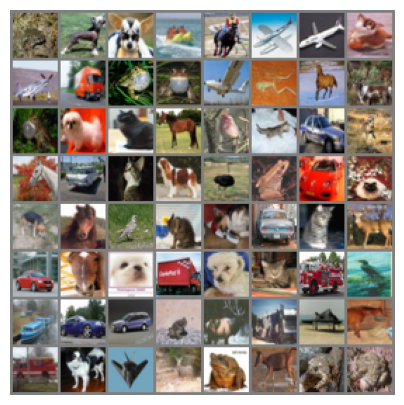

In [34]:
# Get one batch
images, labels = next(iter(train_dataloader))

# Create a grid of images
grid = make_grid(images, nrow=8)
# Denormalize for display
grid = grid * 0.5 + 0.5

# Display
plt.figure(figsize=(5, 5))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.show()

`Conv2d` ფენა გარდაქმნის 3-არხიან გამოსახულებას 16-არხიან feature map-ად, ხოლო `MaxPool2d` ფენა ანახევრებს სიმაღლესა და სიგანეს. Feature map თანდათან მცირდება ახალი ფენების დამატებისას, ბოლოს მივდივართ პატარა feature map-მდე, რომელსაც ვაბრტყელებთ flatten ვექტორად. ამის შემდეგ შეგვიძლია ბოლოში დავამატოთ რამდენიმე fully connected ფენა.

<img src="../../images/cnn_structure.png" width="800" height="400">

In [35]:
class Cifar10Net(nn.Module):
    def __init__(self):
        super(Cifar10Net, self).__init__()
        # Block 1: conv → conv → pool
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)  # 3×32×32 → 32×32×32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) # 32×32×32 → 64×32×32
        self.pool1 = nn.MaxPool2d(2, 2)                          # → 64×16×16

        # Block 2: conv → conv → pool
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)  # → 128×16×16
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1) # → 128×16×16
        self.pool2 = nn.MaxPool2d(2, 2)                            # → 128×8×8

        # Fully connected head
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

        # Optional dropout
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        # Block 1
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool1(x)

        # Block 2
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.pool2(x)

        # Flatten
        x = x.view(x.size(0), -1)  # (batch, 128*8*8)

        # FC head
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

In [36]:
net = Cifar10Net()
net

Cifar10Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)

In [37]:
# მოდელის learnable parameters
params = list(net.parameters())
print(len(params))
print(params[0].size())  # conv1's .weight

14
torch.Size([32, 3, 3, 3])


In [38]:
dummy_input = torch.randn(1, 3, 32, 32)   # batch of 1 CIFAR-10 image
logits = net(dummy_input)
logits.shape     # should be [1, 10]

torch.Size([1, 10])

In [39]:
for images, labels in train_dataloader:
    print("images.shape:", images.shape)
    out = net(images)
    print("out.shape:", out.shape)
    print("out[0]:", out[0])
    break

images.shape: torch.Size([64, 3, 32, 32])
out.shape: torch.Size([64, 10])
out[0]: tensor([ 0.0744, -0.0513, -0.0438,  0.0385,  0.0098,  0.0018,  0.0225, -0.0481,
         0.0398, -0.0903], grad_fn=<SelectBackward0>)


#### CPU / GPU

In [40]:
# Get cpu or gpu device for training
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cpu device


### Training Model

In [41]:
# მოდელი
net = Cifar10Net().to(device)

In [42]:
# ჰიპერპარამეტრები
epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

In [43]:
# Loss function
dummy_input = torch.randn(1, 3, 32, 32) 
dummy_target = torch.randint(0, 10, (1,))  

output = net(dummy_input)
loss = criterion(output, dummy_target)
loss

tensor(2.3411, grad_fn=<NllLossBackward0>)

In [44]:
# Backprop
net.zero_grad()     # zeroes the gradient buffers of all parameters

print(f"conv1.bias.grad before backward: {net.conv1.bias.grad}")
loss.backward()
print(f"conv1.bias.grad after backward: {net.conv1.bias.grad}")

conv1.bias.grad before backward: None
conv1.bias.grad after backward: tensor([ 3.6413e-03,  5.7693e-03, -1.8947e-03,  1.1925e-03, -5.7835e-04,
         1.3209e-04, -2.2839e-03, -1.9378e-03,  2.5481e-03, -2.9432e-03,
         3.5053e-03, -2.7433e-05,  3.4536e-03, -1.3111e-03,  4.8244e-04,
        -3.2205e-03,  1.9290e-03,  1.5281e-03,  2.2884e-05,  2.3339e-03,
         1.5004e-03, -2.4573e-03, -2.4364e-03,  4.5937e-04,  4.9641e-04,
        -2.9372e-03, -7.5877e-04,  1.8181e-03, -3.4278e-03,  2.5621e-04,
         2.4602e-03, -1.1283e-03])


In [45]:
def train(
    model: torch.nn.Module,
    train_loader: torch.utils.data.DataLoader,
    val_loader: torch.utils.data.DataLoader,
    criterion: torch.nn.modules.loss.CrossEntropyLoss,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
    epochs: int,
    scheduler: torch.optim.lr_scheduler._LRScheduler = None,
):
    history = {
        "train_loss": [], "train_acc": [],
        "val_loss":   [], "val_acc":   []
    }

    for epoch in range(1, epochs + 1):

        # ── TRAIN ─────────────────────────────────────────────────────
        model.train()
        running_loss = 0.0
        running_corrects = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            # accumulate stats
            batch_size = inputs.size(0)
            running_loss     += loss.item() * batch_size
            running_corrects += (outputs.argmax(1) == labels).sum().item()
            total_samples    += batch_size

        epoch_train_loss = running_loss / total_samples
        epoch_train_acc  = running_corrects / total_samples

        # ── VALIDATION ────────────────────────────────────────────────
        model.eval()
        val_loss = 0.0
        val_corrects = 0
        val_samples = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                bs = inputs.size(0)
                val_loss     += loss.item() * bs
                val_corrects += (outputs.argmax(1) == labels).sum().item()
                val_samples  += bs

        epoch_val_loss = val_loss / val_samples
        epoch_val_acc  = val_corrects / val_samples

        # ── SCHEDULER ────────────────────────────────────────────────
        if scheduler is not None:
            scheduler.step()

        # ── LOG & HISTORY ────────────────────────────────────────────
        print(
            f"Epoch {epoch:>2}/{epochs}  "
            f"Train: loss={epoch_train_loss:.4f}, acc={epoch_train_acc:.4f}  |  "
            f"Val:   loss={epoch_val_loss:.4f}, acc={epoch_val_acc:.4f}  "
        )

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)
        history["val_loss"].append(epoch_val_loss)
        history["val_acc"].append(epoch_val_acc)

    return history

In [46]:
def evaluate(
    model: torch.nn.Module,
    dataloader: torch.utils.data.DataLoader,
    loss_fn: torch.nn.modules.loss.CrossEntropyLoss,
    device: torch.device,
):
    """
    Runs the model on the entire dataloader and returns:
      - accuracy (float, 0–1)
      - average loss per sample
    """
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = loss_fn(outputs, labels)

            batch_size = inputs.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    print(
        f"Evaluation — "
        f"Accuracy: {accuracy*100:>5.1f}%, "
        f"Avg loss: {avg_loss:>8.4f}"
    )

------ 

In [47]:
# სანამ მოდელს გავწვრთნით, სანამ მოდელი დამოკიდებულებებს ისწავლის შევამოწმოთ
evaluate(net, test_dataloader, criterion, device)

Evaluation — Accuracy:  10.0%, Avg loss:   2.3037


ინიციალური სიზუსტე (initial accuracy) დაახლოებით 10%-ია, რაც მოსალოდნელია შემთხვევით ინიციალიზირებული მოდელისგან (10 კლასიდან სწორად წინასწარ განსაზღვრის 1/10 შანსი აქვს).

In [48]:
# მოდელის გაწვრთნა
history = train(
    net,            # Cifar10Net()
    train_dataloader,     # Train DataLoader
    val_dataloader,       # Val DataLoader
    criterion,        # nn.CrossEntropyLoss()
    optimizer,        # torch.optim.Adam(...)
    device,           # torch.device("cuda")
    epochs=10,
)
print("Done!")

Epoch  1/10  Train: loss=1.7348, acc=0.3543  |  Val:   loss=1.3026, acc=0.5291  
Epoch  2/10  Train: loss=1.2671, acc=0.5490  |  Val:   loss=1.0133, acc=0.6379  
Epoch  3/10  Train: loss=1.0650, acc=0.6278  |  Val:   loss=0.8538, acc=0.6962  
Epoch  4/10  Train: loss=0.9284, acc=0.6829  |  Val:   loss=0.8488, acc=0.7031  
Epoch  5/10  Train: loss=0.8226, acc=0.7191  |  Val:   loss=0.7618, acc=0.7408  
Epoch  6/10  Train: loss=0.7368, acc=0.7505  |  Val:   loss=0.7447, acc=0.7402  
Epoch  7/10  Train: loss=0.6688, acc=0.7738  |  Val:   loss=0.7274, acc=0.7471  
Epoch  8/10  Train: loss=0.6022, acc=0.7960  |  Val:   loss=0.7166, acc=0.7579  
Epoch  9/10  Train: loss=0.5533, acc=0.8119  |  Val:   loss=0.7096, acc=0.7617  
Epoch 10/10  Train: loss=0.5033, acc=0.8293  |  Val:   loss=0.7462, acc=0.7601  
Done!


### Testing with individual images

In [49]:
def predict_image(img, model):
    img = img.to(device)
    xb = img.unsqueeze(0)
    yb = model(xb)
    _, preds  = torch.max(yb, dim=1)
    return testset.classes[preds[0].item()] # Retrieve the class label

Label 1: cat, Predicted 1: cat
Label 2: ship, Predicted 2: ship
Label 3: deer, Predicted 3: horse


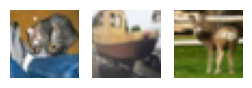

In [50]:
plt.figure(figsize=(3, 1))

img, label = testset[0]
plt.subplot(1, 3, 1)
plt.imshow(img.permute(1, 2, 0)* 0.5 + 0.5)
plt.axis("off")
print(f"Label 1: {testset.classes[label]}, Predicted 1: {predict_image(img, net)}")

img, label = testset[1002]
plt.subplot(1, 3, 2)
plt.imshow(img.permute(1, 2, 0)* 0.5 + 0.5)
plt.axis("off")
print(f"Label 2: {testset.classes[label]}, Predicted 2: {predict_image(img, net)}")

img, label = testset[6153]
plt.subplot(1, 3, 3)
plt.imshow(img.permute(1, 2, 0)* 0.5 + 0.5)
plt.axis("off")
print(f"Label 3: {testset.classes[label]}, Predicted 3: {predict_image(img, net)}")

In [51]:
# ტესტი მთლიან მონაცემებზე
evaluate(net, test_dataloader, criterion, device)

Evaluation — Accuracy:  75.7%, Avg loss:   0.7609


### Model diagnostics

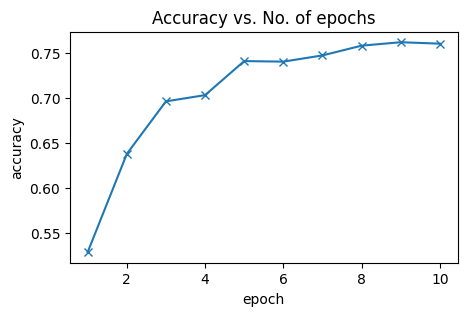

In [53]:
# როგორ უმჯობესდება მეტრიკა 
accuracies = history["val_acc"]

epochs = range(1, len(accuracies) + 1)  # x-axis იწყება 1-დან

plt.figure(figsize=(5, 3))
plt.plot(epochs, accuracies, "-x")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Accuracy vs. No. of epochs")
plt.show()

ჩვენი მოდელი აღწევს დაახლოებით 75%-იან სიზუსტეს, და გრაფიკიდან ჩანს, რომ ხანგრძილივი ტრენინგის მიუხედავად 80%-ს გადაცდენა ნაკლებად სავარაუდოა. ეს მიუთითებს, რომ გამოსახულებებსა და ლეიბლებს შორის კავშირს უკეთ ჩაწვდომა მოითხოვს უფრო ძლიერ არქიტექტურას. ამას შესაძლოა მივაღწიოთ:

* მეტი კონვოლუციური ფენის დამატებით
* თითოეული კონვოლუციური ფენის არხების რაოდენობის გაზრდით
* რეგულიზაციის (მაგალითად, Dropout, Weight Decay) ტექნიკების გამოყენებით

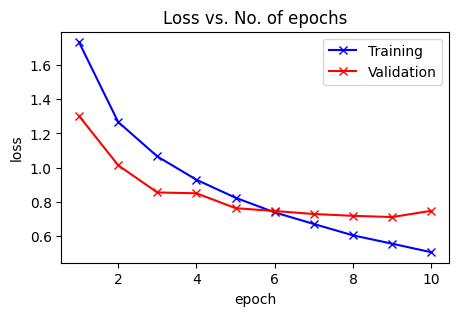

In [54]:
train_losses = history["train_loss"]
val_losses   = history["val_loss"]

epochs = range(1, len(train_losses) + 1)  # x-axis იწყება 1-დან

plt.figure(figsize=(5, 3))
plt.plot(epochs, train_losses, "-bx")
plt.plot(epochs, val_losses, "-rx")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend(["Training", "Validation"])
plt.title("Loss vs. No. of epochs")
plt.show()

overfitting-ის თავიდან ასაცილებლად:

* მეტი სატრენინგო მონაცემების შეგროვება და გენერირება
* რეგულიზაციის ტექნიკების გამოყენება, მაგალითად Batch Normalization და Dropout
* Early stopping–ის გამოყენება — ტრენინგის შეწყვეტა იმ მომენტში, როდესაც ვალიდაციის დანაკარგი იწყებს ზრდას

### Saving and loading the model

In [43]:
# მოდელის შენახვა
torch.save(net.state_dict(), "cifar10-cnn.pth")

In [44]:
# შენახული მოდელის ჩატვირთვა
model = Cifar10Net().to(device) # თავდაპირველად მოდელის განსაზღვრა
model.load_state_dict(torch.load("cifar10-cnn.pth"))

<All keys matched successfully>

In [45]:
# გადავამოწმოთ
evaluate(model, test_dataloader, criterion, device)

Evaluation — Accuracy:  75.6%, Avg loss:   0.7542
